# L15 Nonlinear System of Equations

These notes develop one-dimensional root finding first, then nonlinear systems and inverse kinematics. Definitions, assumptions, derivations, worked examples, and executable experiments are included in the notebook.

Examples have two independent folding levels: open **Example** to see the question, then open **Solution** to see the derivation. 

Run code cells from top to bottom. Required packages: **NumPy, SciPy, Matplotlib**. Figures and results are embedded.

In [1]:
%matplotlib inline
import numpy as np
import numpy.linalg as la
import matplotlib.pyplot as plt
import scipy
import scipy.optimize as opt
from dataclasses import dataclass

plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True,
                     'font.size': 11, 'figure.dpi': 110})
print('NumPy', np.__version__, '| SciPy', scipy.__version__)

NumPy 2.5.4 | SciPy 1.18.1


# I One-Dimensional Nonlinear Equations

## 1. From a physical equation to a zero

- **Spring:** $F=kx$, $k=40\ \mathrm{N/m}$, $F=2\ \mathrm N$, so $x=F/k=0.05\ \mathrm m$.
- **Drag:** $F=\tfrac12C_d\rho A v^2=\mu_dv^2$. With $\mu_d=0.5$ and $F=20$, solve $f(v)=0.5v^2-20=0$. The nonnegative speed is $v=\sqrt{40}\approx6.3249\ \mathrm{m/s}$; the algebraic equation also has a negative root.

## 2. Nonlinear Equations in 1D

### Root Finding

**Goal:** Solve $f(x)=0$ for $f:\mathbb R\to\mathbb R$.

Often called **Root Finding**.

Find the **root (zero)** of the nonlinear function $f$: a number $x^*$ satisfying
$$\boxed{f(x^*)=0}.$$
For the drag-force example,
$$F=\mu_dv^2\quad\Longleftrightarrow\quad
f(v)=\mu_dv^2-F=0.$$
The unknown $v$ is a scalar, and the function value $f(v)$ is also a scalar. This is a one-dimensional nonlinear equation.

More generally, solving $g(x)=b$ is equivalent to finding a zero of $f(x)=g(x)-b$. The function must be evaluated only on its domain. A physical restriction such as $v\ge0$ further determines which mathematical roots are admissible.

**Numerical solution is iterative:** start from a guess or bracket and generate successive approximations. For more complicated functions a closed-form root may be unavailable.

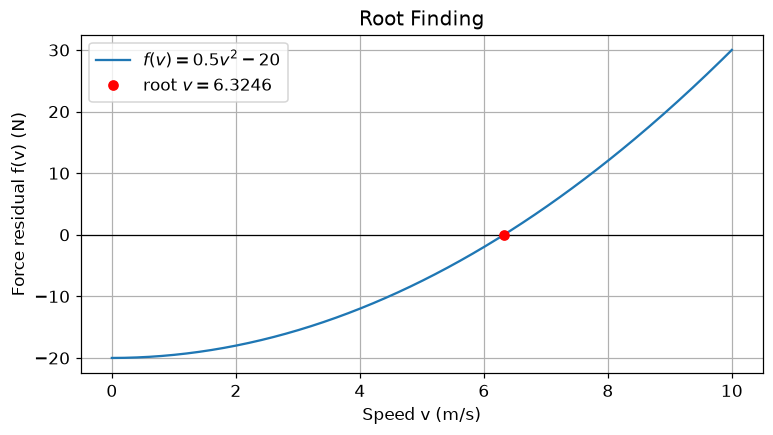

In [2]:
velocity_grid = np.linspace(0., 10., 300)
drag_residual = lambda v: .5*v*v-20.
velocity_root = np.sqrt(40.)
fig, ax = plt.subplots()
ax.plot(velocity_grid, drag_residual(velocity_grid), label=r'$f(v)=0.5v^2-20$')
ax.axhline(0., color='black', lw=.8)
ax.plot(velocity_root, 0., 'ro', label=fr'root $v={velocity_root:.4f}$')
ax.set(xlabel='Speed v (m/s)', ylabel='Force residual f(v) (N)', title='Root Finding')
ax.legend(); plt.show()

For the drag model, $v$ denotes speed and is restricted to $v\ge0$. Writing the physical problem as $f(v)=0$ separates two tasks: choosing a mathematically correct residual and selecting a numerical method for its zero.

A root-finding algorithm starts with a point or an interval and repeatedly constructs a simpler local problem. Bisection uses signs, Newton uses a tangent, and the secant method uses a line through two graph points.

# II Bisection and Convergence

## 1. Bracketing and the bisection update

Suppose $f$ is continuous on $[a_0,b_0]$, and $f(a_0)f(b_0)<0$.
The intermediate value theorem guarantees at least one root in the interval. An endpoint with $f(a_0)=0$ or $f(b_0)=0$ is already a solution.

At each step, set $m=(a+b)/2$ and evaluate $f(m)$. Stop if $f(m)=0$; otherwise retain the half whose endpoints have opposite signs.

**Invariant:** the current interval brackets at least one root, and (unless an exact root is found) its endpoint values have opposite signs. Uniqueness is unnecessary.

After $k$ completed halvings,
$$\boxed{L_k=b_k-a_k=\frac{b_0-a_0}{2^k}}.$$
The interval-width bound contracts linearly with factor $1/2$. If the returned estimate is the midpoint of the final interval,
$$|m_k-x^*|\le\frac{L_k}{2}.$$
The midpoint's actual errors need not have consecutive ratio exactly $1/2$; the guaranteed **width bound** does.

### Algorithm

Given endpoints $a<b$:

1. Evaluate $f(a)$ and $f(b)$. Return an endpoint if its residual is zero; otherwise require opposite signs.
2. Compute $m=a+(b-a)/2$ and evaluate $f(m)$.
3. If $f(m)=0$, return $m$.
4. If $f(a)$ and $f(m)$ have the same sign, replace $a$ by $m$; otherwise replace $b$ by $m$.
5. Repeat until the current interval is smaller than the chosen width tolerance.

The update preserves continuity on the retained subinterval and the sign-changing endpoints, so a root remains enclosed. Each nonterminal update halves the width. Since $L_0/2^k\to0$, arbitrarily small enclosing intervals are obtained in exact arithmetic.

A root enclosure and a numerical estimate can both be returned. Bisection does not need the true root to determine when to stop.

### Bisection interval example

For $f(v)=0.5v^2-20$, choose $[a_0,b_0]=[0,10]$. Since $f(0)=-20$ and $f(10)=30$, the endpoints have opposite signs.

| Halving | Midpoint $m$ | $f(m)$ | Retained interval | Width |
|---|---:|---:|---|---:|
|1|$5$|$-7.5$|$[5,10]$|$5$|
|2|$7.5$|$8.125$|$[5,7.5]$|$2.5$|
|3|$6.25$|$-0.46875$|$[6.25,7.5]$|$1.25$|
|4|$6.875$|$3.6328125$|$[6.25,6.875]$|$0.625$|

Write the interval width as $t_k$. Then
$$t_0=|b_0-a_0|,\quad t_1=\frac{t_0}{2},\quad t_2=\frac{t_0}{2^2},\quad\boxed{t_k=\frac{t_0}{2^k}}.$$
Thus
$$\frac{t_{k+1}}{t_k}=\frac12,\qquad r=1,\quad C=0.5.$$
This is the convergence of the enclosing interval, not a claim that successive midpoint errors always have ratio $1/2$. Stop when $t_k<\mathrm{tol}$.

## 2. Error, residual, and stopping

The **true error** is $e_k=x_k-x^*$. The **residual** is $r_k=f(x_k)$. They are different quantities: near a simple root,
$$f(x_k)\approx f'(x^*)e_k.$$
A small residual need not imply a small error when the derivative is small. True error can be plotted in teaching examples with a known root; a general solver cannot use an unknown $x^*$ as its stopping condition.

We use a residual tolerance, a maximum iteration count, and a stagnation check. A small step with a large residual is reported as failure rather than convergence.

## 3. Order of convergence

An iterative method converges with **rate $r$** if
$$\boxed{\lim_{k\to\infty}\frac{\|e_{k+1}\|}{\|e_k\|^r}=C,\qquad0<C<\infty.}$$
Here $e_k=x_k-x^*$ is the error. The notation $p$ below denotes the same order as $r$.

- $r=1$: **linear convergence**, with $C<1$ needed for contraction.
- $r>1$: **superlinear convergence**.
- $r=2$: **quadratic convergence**.

Linear convergence gains a constant number of accurate digits each step. Quadratic convergence approximately doubles the number of accurate digits each step once the error is sufficiently small. The quadratic model becomes useful only after reaching the local convergence region.

An iteration has order $p$ and asymptotic constant $C$ if
$$\lim_{k\to\infty}\frac{\|e_{k+1}\|}{\|e_k\|^p}=C,\qquad 0<C<\infty.$$

- $p=1$, $0<C<1$: **linear** convergence; roughly a fixed number of accurate digits gained per step.
- $p>1$: **superlinear** convergence.
- $p=2$: **quadratic** convergence; roughly doubles the accurate digits per step once the error is small.

For linear convergence, smaller $C$ means faster asymptotic contraction. For quadratic convergence the factor $\|e_k\|^2$ dominates once $\|e_k\|$ is sufficiently small. These are local/asymptotic statements, not guarantees about the first few iterates.

**Connection to L12.** Power iteration is typically linearly convergent with an eigenvalue-ratio factor $|\lambda_2/\lambda_1|$ (under the usual dominant-eigenvalue assumptions). Here the contraction comes from the root-finding update.

### Why linear and quadratic convergence behave differently

Write $d_k=-\log_{10}|e_k|$ as an approximate count of correct decimal digits once $|e_k|<1$.

For linear convergence $|e_{k+1}|\approx C|e_k|$,
$$d_{k+1}\approx d_k-\log_{10}C.$$
Each step gains approximately the same number of digits. Bisection halves its width bound and therefore gains one binary bit per halving.

For quadratic convergence $|e_{k+1}|\approx C|e_k|^2$,
$$d_{k+1}\approx2d_k-\log_{10}C.$$
Once the error is small, the digit count approximately doubles. This does not mean that Newton must outperform bisection before it reaches its local convergence region.

<details>
<summary>Example: Quadratic error bound</summary>

Assume $|e_{k+1}|<0.5|e_k|^2$ at every step and $|e_0|=0.1$. Find the tightest upper bound for $|e_2|$.


<details>
<summary>Solution</summary>

First $|e_1|<0.5(0.1)^2=0.005$. Then $$|e_2|<0.5(0.005)^2=\boxed{1.25\times10^{-5}}.$$ The strict inequality remains strict. The asymptotic convergence definition alone would not justify a bound at every step; the question explicitly supplies that stronger assumption.

</details>
</details>

<details>
<summary>Example: Interpreting convergence data</summary>

The observed errors are

<table>
<thead>
<tr><th>k</th><th>|e_k|</th></tr>
</thead>
<tbody>
<tr><td>0</td><td>$6.40\times10^{-1}$</td></tr>
<tr><td>1</td><td>$1.94\times10^{-1}$</td></tr>
<tr><td>2</td><td>$6.11\times10^{-2}$</td></tr>
<tr><td>3</td><td>$1.69\times10^{-2}$</td></tr>
<tr><td>4</td><td>$4.86\times10^{-3}$</td></tr>
<tr><td>5</td><td>$1.40\times10^{-3}$</td></tr>
</tbody>
</table>

Estimate the order.


<details>
<summary>Solution</summary>

The ratios $|e_{k+1}|/|e_k|$ approach about $0.29$, whereas the squared-error ratios grow. Thus the data suggest $\boxed{p=1,\ C\approx0.29}$. A finite table is evidence for an asymptotic model, not a proof of the limit.

</details>
</details>

In [3]:
observed_errors = np.array([.640, .194, .0611, .0169, .00486, .00140])
print('linear ratios:', observed_errors[1:] / observed_errors[:-1])
print('quadratic ratios:', observed_errors[1:] / observed_errors[:-1]**2)

linear ratios: [0.303125   0.31494845 0.27659574 0.28757396 0.28806584]
quadratic ratios: [ 0.47363281  1.62344564  4.52693526 17.01621092 59.27280733]


## 4. Iteration counting

For the following iteration counts, use the interval width as the error bound. For strict $L_k<\varepsilon$,
$$k>\log_2\frac{L_0}{\varepsilon},\qquad
k_{\min}=\max\left(0,\left\lfloor\log_2\frac{L_0}{\varepsilon}\right\rfloor+1\right).$$
For $L_k\le\varepsilon$, use $\max(0,\lceil\log_2(L_0/\varepsilon)\rceil)$. For a midpoint-error bound, replace $L_0$ by $L_0/2$.

## 5. Evaluation cost and limitations

Evaluate the two endpoint values once, then only **one new function value per halving**. A separate final midpoint residual check may add one more evaluation. The worst-case width-based count depends on the initial width and tolerance, not the shape of $f$; an exact midpoint root may stop earlier.

Continuity matters: $f(x)=1/x$ has opposite signs on $[-1,1]$ but no root and is undefined at the midpoint. Equal endpoint signs do not prove that no root exists; for example $x^2-1$ on $[-2,2]$ has two roots but no sign-changing bracket.

### Bisection Method: Summary

- The function must be continuous, and the retained interval must contain a root.
- A sign-changing bracket establishes the root enclosure.
- Each iteration requires only one new function evaluation after initialization.
- For an initial interval $[a,b]$, its length after $k$ halvings is $|b-a|/2^k$.
- The enclosing-interval bound has linear convergence with factor $0.5$.

The initial endpoint checks use two function values; evaluating the first midpoint is one additional value. Subsequent endpoint values are reused.

<details>
<summary>Example: valid brackets and iteration counts</summary>

For $f(x)=0.5x^2-2$, use the interval-width stopping condition $L_k<2^{-4}$. Analyze A: $[-10,-1.8]$, B: $[-3,-2.1]$, C: $[-4,1.9]$.


<details>
<summary>Solution</summary>

A brackets $-2$: $L_0=8.2$, so $k>\log_2(131.2)\approx7.04$, giving **8** halvings.

B has both endpoint values positive, so the bisection assumptions fail; the interval contains neither root.

C brackets $-2$: $L_0=5.9$, so $k>\log_2(94.4)\approx6.56$, giving **7** halvings.



</details>
</details>

<details>
<summary>Example: Bisection convergence count</summary>

A continuous function is bracketed by $a=1$, $b=5$. Require interval width strictly smaller than $10^{-4}$. How many halvings suffice?


<details>
<summary>Solution</summary>

$$
\frac4{2^k}<10^{-4}\iff k>\log_2(40000)\approx15.2877.
$$ Therefore $\boxed{k=16}$. The final midpoint has an even smaller guaranteed error, at most $4/(2\cdot2^{16})$.

</details>
</details>

<details>
<summary>Example: Bisection properties</summary>

Which statements are false?
1. It converges when its assumptions hold.
2. It needs two function evaluations at every iteration.
3. It gains one bit of guaranteed bracket accuracy per iteration.
4. For a fixed bracket and requested width, its guaranteed iteration count depends on the particular function.


<details>
<summary>Solution</summary>

**2 and 4 are false.** Endpoint values can be cached, so each halving needs one new evaluation. The width is $L_0/2^k$, independent of the function. Statement 3 refers to the width bound, not monotonic improvement of the actual midpoint error.

</details>
</details>

root: 0.69317626953125 residual: 5.8178788785667734e-05
first 12 widths: [2.000000e+00 1.000000e+00 5.000000e-01 2.500000e-01 1.250000e-01
 6.250000e-02 3.125000e-02 1.562500e-02 7.812500e-03 3.906250e-03
 1.953125e-03 9.765625e-04]
width ratios: [0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5]


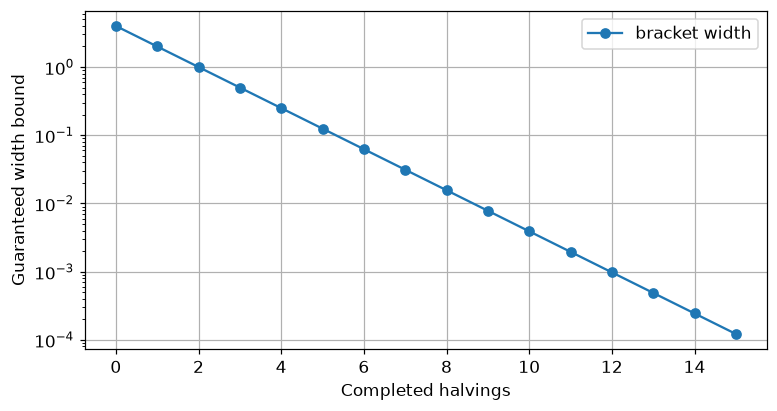

In [4]:
@dataclass(frozen=True)
class ScalarResult:
    root: float
    history: tuple
    residual: float
    widths: tuple = ()

def finite_scalar(f, x):
    value = float(f(x))
    if not np.isfinite(value):
        raise FloatingPointError('Nonfinite function value.')
    return value

def check_controls(tol, maxiter):
    if not np.isfinite(tol) or tol <= 0:
        raise ValueError('Tolerance must be positive and finite.')
    if not isinstance(maxiter, int) or maxiter <= 0:
        raise ValueError('maxiter must be a positive integer.')

def bisection(f, a, b, width_tol=1e-8, maxiter=200):
    check_controls(width_tol, maxiter)
    if not np.isfinite([a, b]).all() or a >= b:
        raise ValueError('Require finite endpoints a < b.')
    fa, fb = finite_scalar(f, a), finite_scalar(f, b)
    if fa == 0 or fb == 0:
        root = a if fa == 0 else b
        return ScalarResult(root, (root,), 0.0, (0.0,))
    if np.signbit(fa) == np.signbit(fb):
        raise ValueError('Endpoints do not form a sign-changing bracket.')
    widths, history = (b-a,), ()
    for _ in range(maxiter):
        m = a + (b-a)/2
        if b-a < width_tol:
            return ScalarResult(m, history+(m,), abs(finite_scalar(f, m)), widths)
        if m == a or m == b:
            raise RuntimeError('Bracket stagnated at floating-point precision.')
        fm = finite_scalar(f, m)
        history = history + (m,)
        if fm == 0:
            return ScalarResult(m, history, 0.0, widths+(0.0,))
        if np.signbit(fa) == np.signbit(fm):
            a, fa = m, fm
        else:
            b, fb = m, fm
        widths = widths + (b-a,)
    # The last allowed halving may already satisfy the tolerance.
    if b-a < width_tol:
        m = a + (b-a)/2
        return ScalarResult(m, history+(m,), abs(finite_scalar(f, m)), widths)
    raise RuntimeError('Bisection did not meet the width tolerance.')

f_exp = lambda x: np.exp(x)-2
D_exp = lambda x: np.exp(x)
root_exp = np.log(2)
bis_exp = bisection(f_exp, -2., 2., width_tol=2.**-12)
print('root:', bis_exp.root, 'residual:', bis_exp.residual)
print('first 12 widths:', np.array(bis_exp.widths[1:13]))
print('width ratios:', np.array(bis_exp.widths[1:]) / bis_exp.widths[:-1])
assert abs(bis_exp.root-root_exp) <= bis_exp.widths[-1]/2
plt.semilogy(bis_exp.widths, 'o-', label='bracket width')
plt.xlabel('Completed halvings'); plt.ylabel('Guaranteed width bound')
plt.legend(); plt.show()

# III Newton's Method in One Dimension

## 1. Newton's method from Taylor expansion

Linearize at $x_k$:
$$f(x_k+s)\approx f(x_k)+f'(x_k)s.$$
Set the linear approximation to zero, solve for $s_k$, and update:
$$\boxed{s_k=-\frac{f(x_k)}{f'(x_k)},\qquad x_{k+1}=x_k+s_k.}$$
Geometrically, $x_{k+1}$ is the horizontal-axis intercept of the tangent at $(x_k,f(x_k))$.

If $f$ is sufficiently smooth, $f(x^*)=0$, $f'(x^*)\ne0$, and the initial guess is sufficiently close, Newton is locally at least quadratic:
$$e_{k+1}=\frac{f''(x^*)}{2f'(x^*)}e_k^2+O(e_k^3).$$
Typically $p=2$; special functions can converge faster or terminate exactly. The asymptotic constant is the absolute value of the coefficient when it is nonzero.
For $f(x)=e^x-2$, the constant is $1/2$.

**Failure modes:** zero derivative away from a root; small derivatives producing huge steps; cycling; divergence; no real root; convergence to an unintended root. A multiple root usually reduces ordinary Newton to linear convergence.

Cost per step: one $f$ evaluation and one $f'$ evaluation, ignoring any shared work between them. Derivative cost is problem-dependent.

## 2. Why Newton is locally quadratic

Assume $f\in C^3$ near a simple root $x^*$ and $f'(x^*)\ne0$. Set $e_k=x_k-x^*$ and write $A=f'(x^*)$, $B=f''(x^*)$.
Taylor expansion around the root gives
$$f(x_k)=Ae_k+\tfrac12Be_k^2+O(e_k^3),$$
$$f'(x_k)=A+Be_k+O(e_k^2).$$
Dividing these expansions,
$$\frac{f(x_k)}{f'(x_k)}=e_k-\frac{B}{2A}e_k^2+O(e_k^3).$$
Subtracting this correction from $e_k$ proves
$$e_{k+1}=\frac{B}{2A}e_k^2+O(e_k^3).$$
The argument requires $e_k$ to be small enough and the derivative to stay away from zero. It proves local behavior, not convergence from every initial guess.

If $f(x)=(x-x^*)^m$ with multiplicity $m>1$, then Newton instead gives
$$e_{k+1}=\left(1-\frac1m\right)e_k,$$
which is linear. Thus the simple-root assumption has a concrete role.

### Newton's Method: Summary

- Start with an initial guess close enough to the root: convergence is only local. Otherwise the method may not converge at all.
- Evaluate the function and its first derivative at each iteration.
- The typical local convergence rate is quadratic:
$$\lim_{k\to\infty}\frac{\|e_{k+1}\|}{\|e_k\|^2}=C,\qquad0<C<\infty.$$
- The Newton step is $h=-f(x_k)/f'(x_k)$, followed by $x_{k+1}=x_k+h$.

**What can we do when evaluating the derivative is too costly or difficult?** Replace the tangent slope by a secant slope obtained from two function values.

<details>
<summary>Example: one Newton step</summary>

Solve $5=2e^x+x^2$ using Newton from $x_0=0$. Find $x_1$.


<details>
<summary>Solution</summary>

Set $f(x)=2e^x+x^2-5$ and $f\prime(x)=2e^x+2x$. Then $f(0)=-3$, $f\prime(0)=2$, so $$x_1=0-\frac{-3}{2}=\boxed{1.5}.$$

</details>
</details>

<details>
<summary>Example: Two Newton iterations</summary>

For $f(x)=x^3-x+2$ and $x_0=1$, calculate $x_2$.


<details>
<summary>Solution</summary>

$$
x_1=1-\frac{2}{2}=0,\qquad x_2=0-\frac{2}{-1}=\boxed{2}.
$$ 
This illustrates that an iteration need not move monotonically toward a root.

</details>
</details>

<details>
<summary>Example: Where will Newton fail?</summary>

Which of these real root-finding problems fails from the given start?
- A: $1.5x^3-0.5x+2$, $x_0=0.5$.
- B: $x^3+2-\sin x$, $x_0=-1$.
- C: $x^2+3$, $x_0=1$.
- D: $2x-x^2$, $x_0=1$.


<details>
<summary>Solution</summary>

**C and D.** C has no real zero. D has $f(1)=1$ and $f\prime(1)=0$, making the Newton step undefined. A and B converge for these starts (verified below). A nonzero starting derivative alone is not a general convergence guarantee; it merely rules out immediate division by zero.

</details>
</details>

In [5]:
def newton_scalar(f, df, x0, tol=1e-12, maxiter=100):
    check_controls(tol, maxiter)
    x = float(x0)
    if not np.isfinite(x):
        raise ValueError('Initial guess must be finite.')
    history = (x,)
    for _ in range(maxiter):
        fx = finite_scalar(f, x)
        if abs(fx) <= tol:
            return ScalarResult(x, history, abs(fx))
        slope = finite_scalar(df, x)
        if slope == 0:
            raise ZeroDivisionError('Zero derivative away from a root.')
        x_new = x - fx/slope
        if not np.isfinite(x_new):
            raise FloatingPointError('Nonfinite Newton iterate.')
        if x_new == x:
            raise RuntimeError('Newton stagnated with a large residual.')
        x, history = x_new, history+(x_new,)
    fx = finite_scalar(f, x)
    if abs(fx) <= tol:
        return ScalarResult(x, history, abs(fx))
    raise RuntimeError('Newton reached its iteration limit.')

new_exp = newton_scalar(f_exp, D_exp, 2.)
print('exponential root:', new_exp.root)
for name, f, df, start in (
    ('A', lambda x:1.5*x**3-.5*x+2, lambda x:4.5*x*x-.5, .5),
    ('B', lambda x:x**3+2-np.sin(x), lambda x:3*x*x-np.cos(x), -1.)):
    result = newton_scalar(f, df, start)
    print(name, 'root:', result.root, 'residual:', result.residual)

exponential root: 0.6931471805599453
A root: -1.2013361798309863 residual: 9.943157408542902e-13
B root: -1.440898214151963 residual: 5.551115123125783e-16


# IV Secant Method

## 1. Replace the derivative by a divided difference

Using two successive iterates,
$$d_k=\frac{f(x_k)-f(x_{k-1})}{x_k-x_{k-1}},$$
$$\boxed{x_{k+1}=x_k-f(x_k)\frac{x_k-x_{k-1}}{f(x_k)-f(x_{k-1})}.}$$
This is the zero of the line through the two most recent graph points. Unlike bisection, the two guesses need not bracket a root; no bracket invariant is maintained.

Under standard smoothness and simple-root assumptions, sufficiently close starts yield generic order
$$p=\varphi=\frac{1+\sqrt5}{2}\approx1.618.$$
A proof sketch: the leading error model is $e_{k+1}\approx K e_ke_{k-1}$. Matching powers using $|e_k|\sim C |e_{k-1}|^p$ gives $p=1+1/p$, hence $p^2-p-1=0$.

Two initial function values are needed; caching makes later steps cost **one new function evaluation** each. A zero difference $f(x_k)-f(x_{k-1})$ makes the step undefined. Convergence remains local.

### Secant Method: Summary

- It still has only local convergence.
- It requires two starting guesses.
- Two initial function values are needed; each later step requires only one new function evaluation when previous values are cached.
- Its typical convergence is slower than Newton's method but faster than a linear method near a simple root: it is superlinear, with $1<r<2$ and generic order $r\approx1.618$.

The derivative approximation is
$$\operatorname{df}_k=\frac{f(x_k)-f(x_{k-1})}{x_k-x_{k-1}},\qquad
h_k=-\frac{f(x_k)}{\operatorname{df}_k},\qquad x_{k+1}=x_k+h_k.$$
This has the same update structure as Newton; only the slope used in the local linear model changes.

<details>
<summary>Example: Secant formula for square roots</summary>

Apply the secant method to $f(x)=x^2-R$. Simplify the update.


<details>
<summary>Solution</summary>

Since $x_k^2-x_{k-1}^2=(x_k-x_{k-1})(x_k+x_{k-1})$,
$$x_{k+1}=x_k-\frac{x_k^2-R}{x_k+x_{k-1}}
=\boxed{\frac{x_kx_{k-1}+R}{x_k+x_{k-1}}}.$$
This uses two iterates. By contrast, Newton gives $x_{k+1}=\tfrac12(x_k+R/x_k)$. Cancellation assumes the original divided difference is defined.

</details>
</details>

<details>
<summary>Example: Secant convergence</summary>

Is secant iteration linear, quadratic, superlinear but not quadratic, or sublinear?


<details>
<summary>Solution</summary>

Under the usual local simple-root assumptions, its generic order is $\varphi\approx1.618$: **superlinear but not quadratic**. This classification does not assert convergence from arbitrary starts.

</details>
</details>

Newton local error ratios: [0.49846962 0.49999295]
Secant local error ratios: [0.6811602  0.62598146 0.66690324 0.64222155]


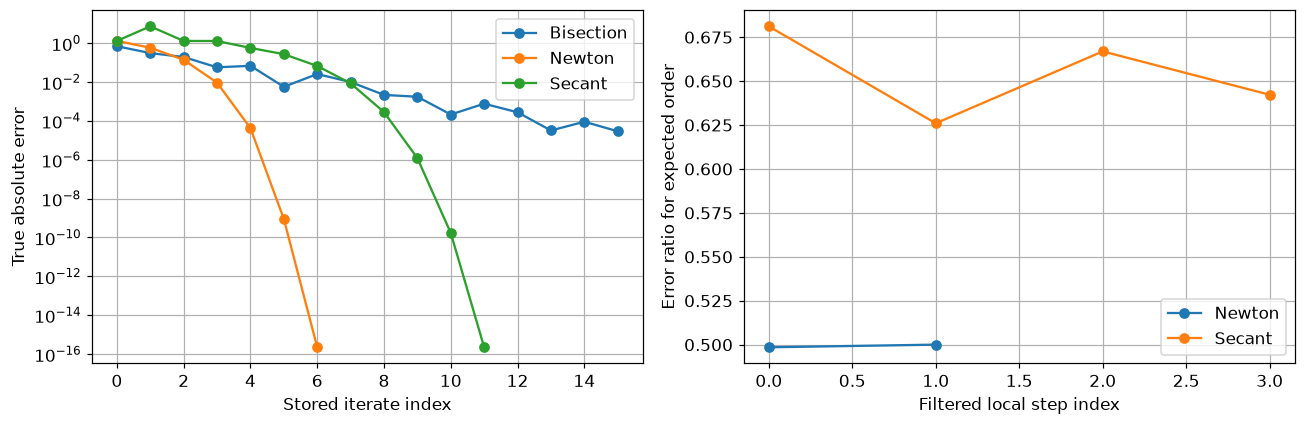

In [6]:
def secant(f, x0, x1, tol=1e-12, maxiter=100):
    check_controls(tol, maxiter)
    a, b = float(x0), float(x1)
    if not np.isfinite([a, b]).all() or a == b:
        raise ValueError('Require distinct finite initial guesses.')
    fa, fb = finite_scalar(f, a), finite_scalar(f, b)
    history = (a, b)
    if abs(fa) <= tol:
        return ScalarResult(a, (a,), abs(fa))
    for _ in range(maxiter):
        if abs(fb) <= tol:
            return ScalarResult(b, history, abs(fb))
        if fb == fa:
            raise ZeroDivisionError('Zero secant divided difference.')
        c = b - fb*(b-a)/(fb-fa)
        if not np.isfinite(c):
            raise FloatingPointError('Nonfinite secant iterate.')
        if c == b:
            raise RuntimeError('Secant stagnated with a large residual.')
        a, fa, b, fb = b, fb, c, finite_scalar(f, c)
        history = history+(c,)
    if abs(fb) <= tol:
        return ScalarResult(b, history, abs(fb))
    raise RuntimeError('Secant reached its iteration limit.')

sec_exp = secant(f_exp, 2., 8.)  # two starting guesses
phi = (1+np.sqrt(5))/2
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, result in [('Bisection', bis_exp), ('Newton', new_exp), ('Secant', sec_exp)]:
    error = np.abs(np.asarray(result.history)-root_exp)
    axes[0].semilogy(np.maximum(error, np.finfo(float).eps), 'o-', label=name)
for name, result, order in [('Newton', new_exp, 2.), ('Secant', sec_exp, phi)]:
    error = np.abs(np.asarray(result.history)-root_exp)
    mask = (error[:-1]>1e-7) & (error[:-1]<.1) & (error[1:]>1e-14)
    ratio = error[1:][mask]/error[:-1][mask]**order
    print(name, 'local error ratios:', ratio)
    axes[1].plot(np.arange(len(ratio)), ratio, 'o-', label=name)
axes[0].set(xlabel='Stored iterate index', ylabel='True absolute error')
axes[1].set(xlabel='Filtered local step index', ylabel='Error ratio for expected order')
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

# V Comparison and One-Dimensional Experiments

## 1. Method summary

| Method | Required starting information | Generic convergence | New work per iteration | Main limitation |
|---|---|---|---|---|
| Bisection | Continuous function and sign-changing bracket | Width bound linear, $C=1/2$ | One new $f$ value after endpoint setup | Requires a bracket and reduces width slowly |
| Newton | One sufficiently close guess and a derivative | Locally quadratic at a simple root | One $f$ and one $f'$ value | Derivative may vanish; arbitrary starts may fail |
| Secant | Two sufficiently close guesses | Locally superlinear, $p=(1+\sqrt5)/2$ | One new $f$ value after two startup values | Divided difference may vanish; no enclosure guarantee |

Bisection trades speed for a guaranteed enclosure under its assumptions. Newton and secant exploit local smoothness and can converge much faster after entering the attraction region of a root. Cost comparisons must include the cost of derivatives, not just the number of iterations.

The comparison uses the starting values: Newton at $2$, secant at $(2,8)$, and bisection on $[-2,2]$. This compares behavior, not equal evaluation budgets. Error-ratio estimates exclude large initial errors and values near floating-point roundoff; secant ratios can oscillate before their asymptotic regime.

## 2. SciPy equivalents

`root_scalar` exposes scalar methods. Set the method explicitly to make the experiment reproducible. A bracketed Brent solve combines bracketing safeguards with interpolation; it is included as the practical bracketed alternative for comparison.

In [7]:
scalar_scipy = {
    'bisect': opt.root_scalar(f_exp, bracket=(-2, 3), method='bisect'),
    'brentq': opt.root_scalar(f_exp, bracket=(-2, 3), method='brentq'),
    'newton': opt.root_scalar(f_exp, x0=3., fprime=D_exp, method='newton'),
    'secant': opt.root_scalar(f_exp, x0=3., x1=4., method='secant'),
}
for name, result in scalar_scipy.items():
    assert result.converged and abs(f_exp(result.root)) < 1e-8
    print(f'{name:8} root={result.root:.12f}, iterations={result.iterations}, '
          f'function_calls={result.function_calls}')

bisect   root=0.693147180561, iterations=42, function_calls=44
brentq   root=0.693147180560, iterations=9, function_calls=10
newton   root=0.693147180560, iterations=7, function_calls=14
secant   root=0.693147180560, iterations=11, function_calls=12


## 3. Cubic example: tangent and secant geometry

For $f(x)=x^3-x+1$, the real root is approximately $-1.324717957244746$.
The first three updates are drawn automatically. Both methods are also run to convergence with an iteration limit. Poor initial tangents can send iterates far outside the displayed window.

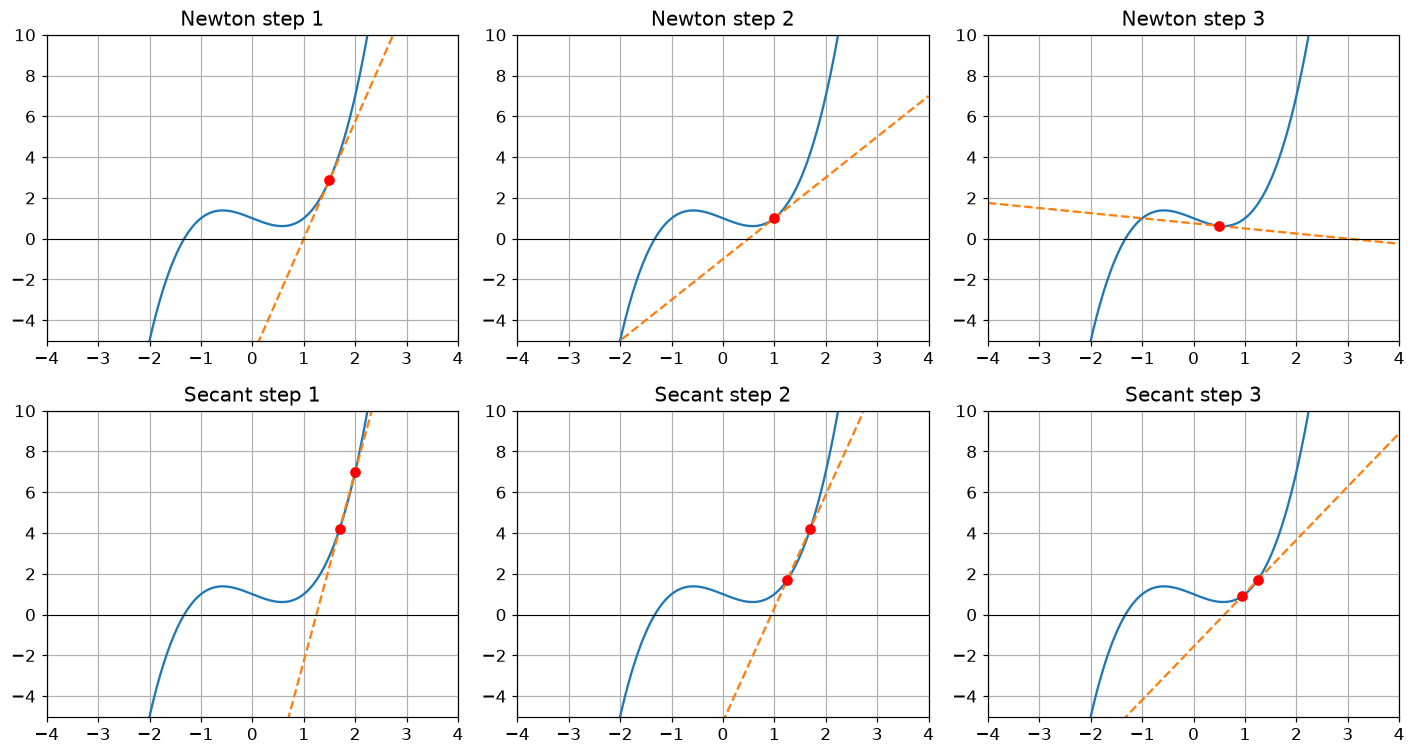

Newton root: -1.324717957244746 | Secant root: -1.3247179572447463


In [8]:
f_cubic = lambda x: x**3-x+1
D_cubic = lambda x: 3*x*x-1
cubic_new = newton_scalar(f_cubic, D_cubic, 1.5, maxiter=200)
cubic_sec = secant(f_cubic, 2., 1.7, maxiter=200)
mesh = np.linspace(-4., 4., 500)
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for j in range(3):
    xn = cubic_new.history[j]
    xs0, xs1 = cubic_sec.history[j:j+2]
    tangent = f_cubic(xn)+D_cubic(xn)*(mesh-xn)
    slope = (f_cubic(xs1)-f_cubic(xs0))/(xs1-xs0)
    chord = f_cubic(xs1)+slope*(mesh-xs1)
    for ax, line, title in [(axes[0,j], tangent, f'Newton step {j+1}'),
                            (axes[1,j], chord, f'Secant step {j+1}')]:
        ax.plot(mesh, f_cubic(mesh), label='f')
        ax.plot(mesh, line, '--', label='linear model')
        ax.axhline(0, color='black', lw=.7)
        ax.set(xlim=(-4,4), ylim=(-5,10), title=title)
    axes[0,j].plot(xn, f_cubic(xn), 'ro')
    axes[1,j].plot([xs0,xs1], [f_cubic(xs0),f_cubic(xs1)], 'ro')
plt.tight_layout(); plt.show()
print('Newton root:', cubic_new.root, '| Secant root:', cubic_sec.root)

# VI Nonlinear Systems of Equations

## Motivation: robotic arms

A planar robotic arm provides a motivating example. Given a desired hand location $(x_t,y_t)$ and orientation $\beta$, find joint angles $(\theta_1,\theta_2,\theta_3)$. Each angle affects the geometry, so the equations must be solved together. The unknown is a vector, and the residual is a vector of equations.

We first develop the general Newton method for $n$ equations in $n$ unknowns. We then apply it to this inverse-kinematics problem, including its geometric derivation.

### Robotic arm demonstrations

Optional motion examples: [Robotic arm 1](https://www.youtube.com/watch?v=NRgNDlVtmz0), [Robotic arm 2](https://www.youtube.com/watch?v=9DqRkLQ5Sv8), and [Blender arm animation](https://www.youtube.com/watch?v=DZ_ocmY8xEI). The equations and derivations needed here are all included below.

## 1. Model and representation

**Goal:** Solve $\mathbf f(\mathbf x)=\mathbf0$ for $\mathbf f:\mathbb R^n\to\mathbb R^n$.

A nonlinear system has $n$ unknowns and $n$ scalar residual equations. We also write the vector-valued function as uppercase $F$ below.

For $F:\mathbb R^n\to\mathbb R^n$, solve
$$F(\mathbf x)=\begin{bmatrix}F_1(\mathbf x)\\\vdots\\F_n(\mathbf x)\end{bmatrix}=\mathbf0.$$
Each component equation contributes one residual. For example, the system
$$x_1^2+2x_1x_2+x_2^3=4,\quad2x_1+3x_2=5,$$
can be written as $F=(x_1^2+2x_1x_2+x_2^3-4,\ 2x_1+3x_2-5)^T$.
Multiplying a residual equation by $-1$ preserves its roots, provided its Jacobian row is changed consistently.

## 2. The Jacobian

The **Jacobian** has rows indexed by equations and columns indexed by variables:
$$\boxed{J_{ij}(\mathbf x)=\frac{\partial F_i}{\partial x_j}(\mathbf x)}.$$
It is the derivative of a vector-valued map; it is not the scalar-function gradient from optimization.

## 3. Derive the multidimensional Newton step

First-order Taylor expansion gives
$$F(\mathbf x_k+\mathbf s)\approx F(\mathbf x_k)+J(\mathbf x_k)\mathbf s.$$
Setting this model to zero yields
$$\boxed{J(\mathbf x_k)\mathbf s_k=-F(\mathbf x_k),\qquad
\mathbf x_{k+1}=\mathbf x_k+\mathbf s_k.}$$
**Solve a linear system** with `la.solve(J, -F)`; do not form an explicit inverse. The equivalent convention $J\mathbf h=F$, $\mathbf x_{k+1}=\mathbf x_k-\mathbf h$ works too. Mixing these signs is a common error.

For sufficiently smooth $F$, an invertible $J(\mathbf x^*)$, and a sufficiently close start, Newton is locally at least quadratic. Singular Jacobians, poor starts, or no solution can defeat convergence.

## 4. Newton iteration as a sequence of linear systems

Starting from a vector $\mathbf x_0$, repeat:

1. Evaluate the residual $\mathbf r_k=F(\mathbf x_k)$.
2. Evaluate $J_k=J(\mathbf x_k)$.
3. Factorize the current Jacobian, for example $P_kJ_k=L_kU_k$.
4. Solve $L_kU_k\mathbf s_k=-P_k\mathbf r_k$ using forward and backward substitution.
5. Set $\mathbf x_{k+1}=\mathbf x_k+\mathbf s_k$.
6. Check the residual, finite values, and iteration limit.

For $n=1$, the linear solve becomes division by $f'(x_k)$, recovering scalar Newton. For $n>1$, the correction accounts for all variable couplings through the off-diagonal Jacobian entries.

A different Jacobian is generally required at each iterate. Reusing an old factorization changes the method unless the Jacobian itself is unchanged.

<details>
<summary>Example: Calculate a Jacobian</summary>

For $F(x_1,x_2)=(x_1^2-x_2^2,\ x_2^3-2)^T$, evaluate $J$ at $(3,-3)$.


<details>
<summary>Solution</summary>

$$
J=\begin{bmatrix}2x_1&-2x_2\\0&3x_2^2\end{bmatrix},\qquad J(3,-3)=\boxed{\begin{bmatrix}6&6\\0&27\end{bmatrix}}.$$ 
The zero entry follows because the second equation is independent of $x_1$.

</details>
</details>

<details>
<summary>Example: one 2D Newton iteration</summary>

Solve $x+2y=2$, $x^2+4y^2=4$ from $\mathbf x_0=(1,0)^T$.


<details>
<summary>Solution</summary>

$$F(1,0)=(-1,-3)^T,\quad J(1,0)=\begin{bmatrix}1&2\\2&0\end{bmatrix}.$$
Solve $s_1+2s_2=1$, $2s_1=3$, obtaining $\mathbf s=(1.5,-0.25)^T$.
Therefore $\boxed{\mathbf x_1=(2.5,-0.25)^T}$.

</details>
</details>

<details>
<summary>Example: Calculate the Newton step vector</summary>

Let $F(x_1,x_2)=(x_1^2-2x_1x_2+x_2^2-7,\ x_2^3-2x_1)^T$ and $\mathbf x_0=(3,2)^T$. Find the step $\mathbf s$.


<details>
<summary>Solution</summary>

At $(3,2)$,
$$F=\begin{bmatrix}-6\\2\end{bmatrix},\quad
J=\begin{bmatrix}2x_1-2x_2&-2x_1+2x_2\\-2&3x_2^2\end{bmatrix}
=\begin{bmatrix}2&-2\\-2&12\end{bmatrix}.$$
Solve $2s_1-2s_2=6$, $-2s_1+12s_2=-2$, giving
$$\boxed{\mathbf s=(3.4,0.4)^T},\qquad \mathbf x_1=(6.4,2.4)^T.$$
The requested **step** is not the new iterate.

</details>
</details>

<details>
<summary>Example: Triangular Newton system</summary>

For $x+2=0$, $5x^2+y=5$, start at $(1,0)^T$. Find $J(\mathbf x_0)$ and $\mathbf x_1$.


<details>
<summary>Solution</summary>

$$F(1,0)=(3,0)^T,\quad J(x,y)=\begin{bmatrix}1&0\\10x&1\end{bmatrix},\quad
J(1,0)=\boxed{\begin{bmatrix}1&0\\10&1\end{bmatrix}}.$$
Forward substitution gives $s_x=-3$, $10s_x+s_y=0\implies s_y=30$.
Thus $\boxed{\mathbf x_1=(-2,30)^T}$.
The exact root is $(-2,-15)^T$; a second Newton step reaches it. A large first residual is compatible with eventual convergence.

</details>
</details>

## 5. Work per iteration

- Evaluate $F$ and assemble $J$.
- For a dense $n\times n$ Jacobian, factorization typically costs $O(n^3)$; triangular solves cost $O(n^2)$.
- There are $n^2$ scalar derivative entries in a dense Jacobian. Counting individual scalar derivatives gives $n^2$ entries; their actual computation cost depends on the formulas or differentiation method.
- A forward-difference Jacobian takes $n+1$ **vector** evaluations of $F$ (or $n$ new ones with cached $F(\mathbf x)$). Each vector evaluation computes $n$ scalar residual components, so the scalar-component count is $O(n^2)$. These are different cost units.
- Sparse Jacobians may be cheaper. Reusing a frozen Jacobian/factorization saves work per step but generally sacrifices quadratic convergence; this is a modified/chord Newton method.

<details>
<summary>Example: Newton cost: identify the unit</summary>

For dense $n$-dimensional Newton, assess:
A. Cost per iteration is $O(n^3)$.
B. Newton always converges.
C. At most $O(n)$ function evaluations are needed per iteration.
D. Convergence is usually quadratic.


<details>
<summary>Solution</summary>

Under the standard dense-solve cost model, **A is true**, **B is false**, and **D is true locally under regularity assumptions**. C needs a cost unit: it is true for $O(n)$ evaluations of the **vector residual** when constructing a forward-difference Jacobian; it is false if “function evaluations” means individual scalar-component/derivative work, which is generally $O(n^2)$ for a dense Jacobian. Using the scalar-component cost convention, **A and D are the intended selections**. State the convention rather than conflating the counts.

</details>
</details>

## 6. Executable Newton method

In [9]:
@dataclass(frozen=True)
class SystemResult:
    root: np.ndarray
    history: tuple
    residuals: tuple

def newton_system(F, J, x0, tol=1e-11, maxiter=50):
    check_controls(tol, maxiter)
    x = np.array(x0, dtype=float, copy=True)
    if x.ndim != 1 or not np.isfinite(x).all():
        raise ValueError('Initial guess must be a finite vector.')
    history, residuals = (x.copy(),), ()
    for _ in range(maxiter+1):
        fx = np.asarray(F(x), dtype=float)
        if fx.shape != x.shape or not np.isfinite(fx).all():
            raise ValueError('Residual must be a finite vector matching x.')
        residual = float(la.norm(fx, ord=np.inf))
        residuals = residuals+(residual,)
        if residual <= tol:
            return SystemResult(x.copy(), history, residuals)
        if len(history)-1 == maxiter:
            break
        jac = np.asarray(J(x), dtype=float)
        if jac.shape != (x.size, x.size) or not np.isfinite(jac).all():
            raise ValueError('Jacobian must be a finite square matrix.')
        step = la.solve(jac, -fx)  # raises LinAlgError if singular
        x_new = x+step
        if not np.isfinite(x_new).all():
            raise FloatingPointError('Nonfinite Newton iterate.')
        if np.array_equal(x_new, x):
            raise RuntimeError('Newton stagnated with a large residual.')
        x, history = x_new, history+(x_new.copy(),)
    raise RuntimeError('System Newton reached its iteration limit.')

def F_system(xvec):
    x, y = xvec
    return np.array([x+2*y-2, x*x+4*y*y-4])

def J_system(xvec):
    x, y = xvec
    return np.array([[1., 2.], [2*x, 8*y]])

slide_start = np.array([1., 0.])
slide_next = slide_start + la.solve(J_system(slide_start), -F_system(slide_start))
assert np.allclose(slide_next, [2.5, -.25])
sys_left = newton_system(F_system, J_system, [1., 2.])
sys_right = newton_system(F_system, J_system, [3., 0.])
print('from [1,2]:', sys_left.root, '| from [3,0]:', sys_right.root)

from [1,2]: [-1.6237462e-17  1.0000000e+00] | from [3,0]: [2.00000000e+00 5.66864702e-17]


## 7. Two roots and two basins

For the system,
$$x=2-2y\quad\Longrightarrow\quad(2-2y)^2+4y^2-4=8y(y-1)=0.$$
Thus there are **two** real roots: $(0,1)$ and $(2,0)$. The initial guess $[1,2]^T$ leads to $(0,1)$; another starting point can lead to $(2,0)$.

The determinant is $8y-4x$. On $x=2y$, the Jacobian is singular. In particular, $(1,0.5)$ lies on the linear equation but does not solve the nonlinear system and is an invalid Newton start.

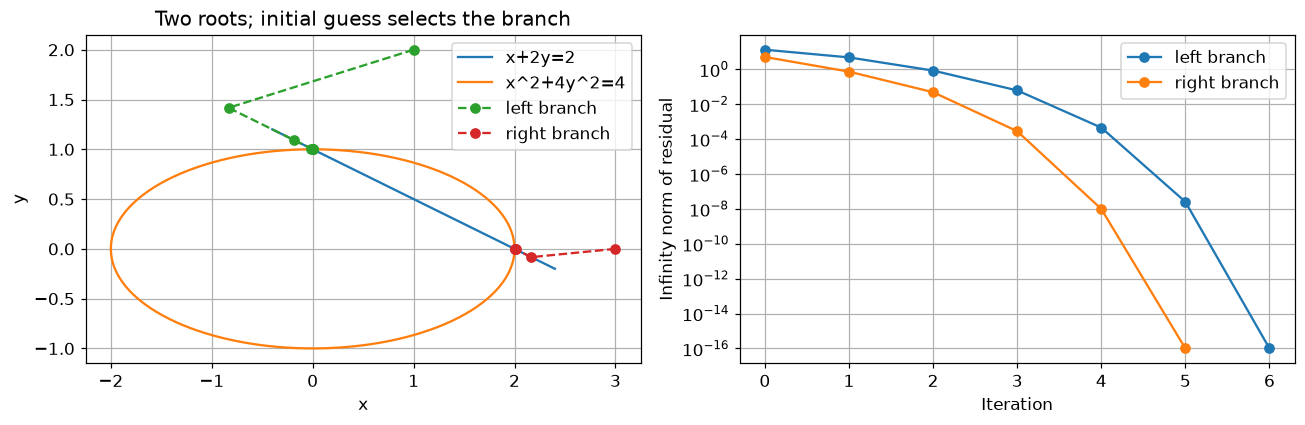

true errors: [1.41421356e+00 9.31694991e-01 2.11748862e-01 1.68589858e-02
 1.25221236e-04 7.01168384e-09 1.62374620e-17]
quadratic ratios: [0.44057018 0.44716351]


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ycurve = np.linspace(-.2, 1.2, 300)
theta = np.linspace(0, 2*np.pi, 400)
axes[0].plot(2-2*ycurve, ycurve, label='x+2y=2')
axes[0].plot(2*np.cos(theta), np.sin(theta), label='x^2+4y^2=4')
for name, result in [('left branch',sys_left), ('right branch',sys_right)]:
    pts = np.asarray(result.history)
    axes[0].plot(pts[:,0], pts[:,1], 'o--', label=name)
    axes[1].semilogy(np.maximum(result.residuals, 1e-16), 'o-', label=name)
axes[0].set(xlabel='x', ylabel='y', title='Two roots; initial guess selects the branch')
axes[1].set(xlabel='Iteration', ylabel='Infinity norm of residual')
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()
true_errors = la.norm(np.asarray(sys_left.history)-np.array([0.,1.]), axis=1)
print('true errors:', true_errors)
mask = (true_errors[:-1]>1e-7) & (true_errors[:-1]<.1)
print('quadratic ratios:', true_errors[1:][mask]/true_errors[:-1][mask]**2)

## 8. Finite-difference Jacobian: connection to L14

When analytic derivatives are unavailable, approximate **column $j$** by
$$J_{:,j}(\mathbf x)\approx\frac{F(\mathbf x+h_j\mathbf e_j)-F(\mathbf x)}{h_j}.$$
Forward differences have $O(h_j)$ truncation error, opposed by roundoff amplification when $h_j$ is too small. A fixed approximate Jacobian accuracy need not preserve exact quadratic convergence all the way to a root.

The code below constructs new perturbed vectors; the caller's input is never changed. The default step scales with the variable magnitude and uses roughly $\sqrt{\epsilon_{\rm mach}}$ for a forward difference. We also compare the fixed step $h=10^{-4}$ with the analytic Jacobian.

analytic:
 [[ 1.  2.]
 [ 8. 16.]]
forward difference, h=1e-4:
 [[ 1.      2.    ]
 [ 8.0001 16.0004]]
FD Newton root: [-2.28504933e-13  1.00000000e+00] | residual: 9.14823772291129e-13


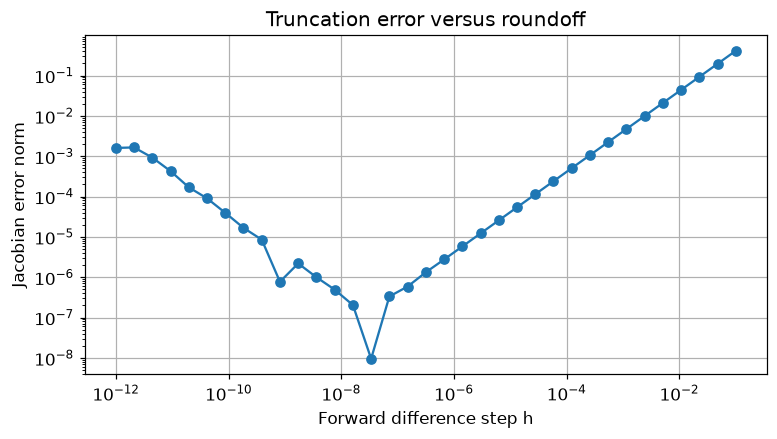

In [11]:
def fd_jacobian(F, xvec, h=None):
    x = np.asarray(xvec, dtype=float)
    if x.ndim != 1 or not np.isfinite(x).all():
        raise ValueError('x must be a finite vector.')
    if h is not None and (not np.isfinite(h) or h <= 0):
        raise ValueError('Finite difference step must be positive.')
    fx = np.asarray(F(x), dtype=float)
    steps = (np.sqrt(np.finfo(float).eps)*np.maximum(1., np.abs(x))
             if h is None else np.full(x.size, h))
    basis = np.eye(x.size)
    columns = tuple((np.asarray(F(x+steps[j]*basis[j]))-fx)/steps[j]
                    for j in range(x.size))
    return np.column_stack(columns)

probe = np.array([4., 2.])
probe_saved = probe.copy()
print('analytic:\n', J_system(probe))
print('forward difference, h=1e-4:\n', fd_jacobian(F_system, probe, 1e-4))
assert np.array_equal(probe, probe_saved)
sys_fd = newton_system(F_system, lambda x:fd_jacobian(F_system, x, 1e-4), [1.,2.])
print('FD Newton root:', sys_fd.root, '| residual:', sys_fd.residuals[-1])
steps = np.logspace(-12, -1, 35)
fd_errors = [la.norm(fd_jacobian(F_system, probe, h)-J_system(probe)) for h in steps]
plt.loglog(steps, fd_errors, 'o-')
plt.xlabel('Forward difference step h'); plt.ylabel('Jacobian error norm')
plt.title('Truncation error versus roundoff'); plt.show()

# VII Inverse Kinematics

## 1. Geometry and equations

### Joint geometry and original angle notation

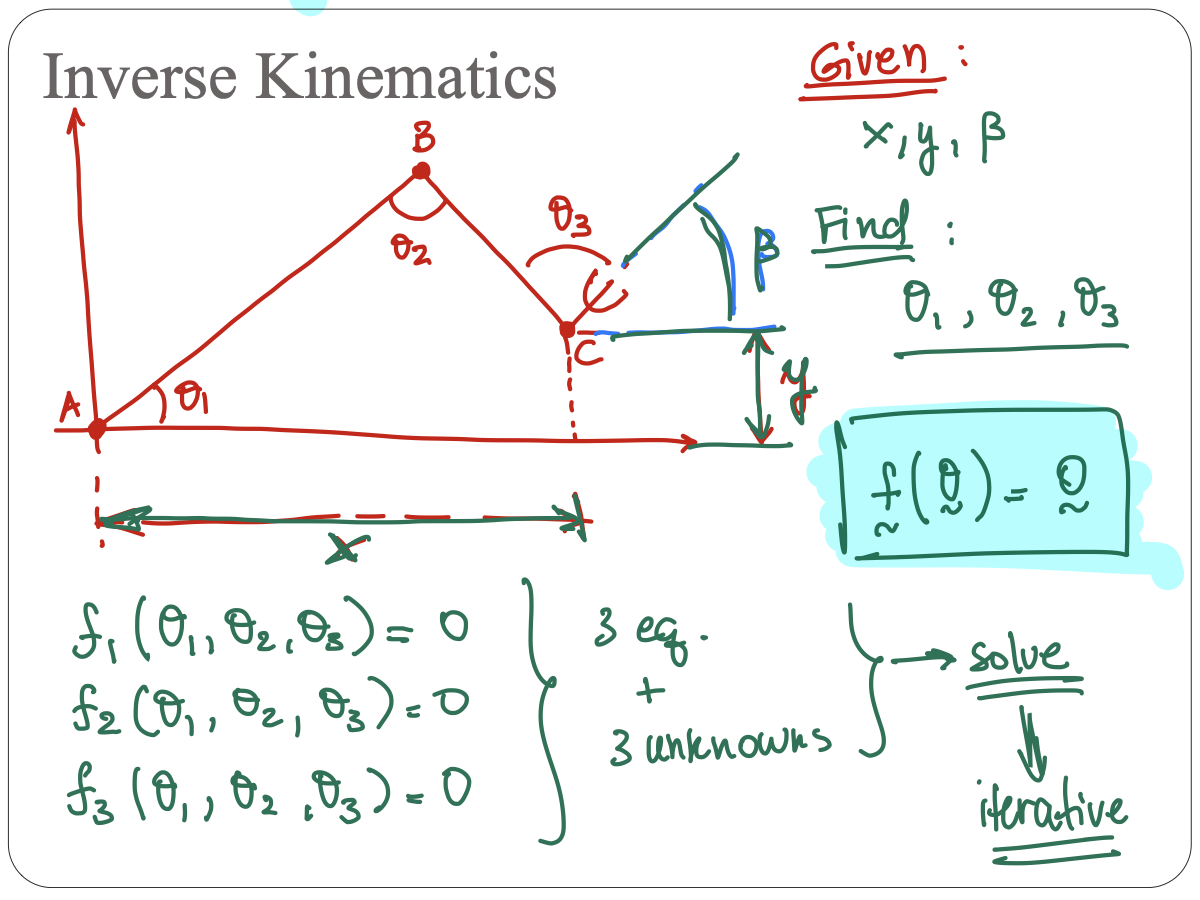

**Given:** the hand position $(x_t,y_t)$ and orientation $\beta$, together with link lengths $a,b$.

**Find:** the joint angles $\theta_1,\theta_2,\theta_3$.

Three unknown angles require three equations:
$$f_1(\theta_1,\theta_2,\theta_3)=0,\quad
f_2(\theta_1,\theta_2,\theta_3)=0,\quad
f_3(\theta_1,\theta_2,\theta_3)=0.$$

Introduce the triangle side and angles
$$c=\sqrt{x_t^2+y_t^2},\qquad
\alpha_2=\tan^{-1}(y_t/x_t),\qquad
\theta_1=\alpha_1+\alpha_2,\qquad
\alpha_1=\theta_1-\alpha_2.$$
The displayed arctangent formula applies to the illustrated quadrant. For general coordinates, compute $\alpha_2=\operatorname{atan2}(y_t,x_t)$. The symbol $\alpha$ used in the implementation below is this same $\alpha_2$.

### Cosine-rule equations and angle sum

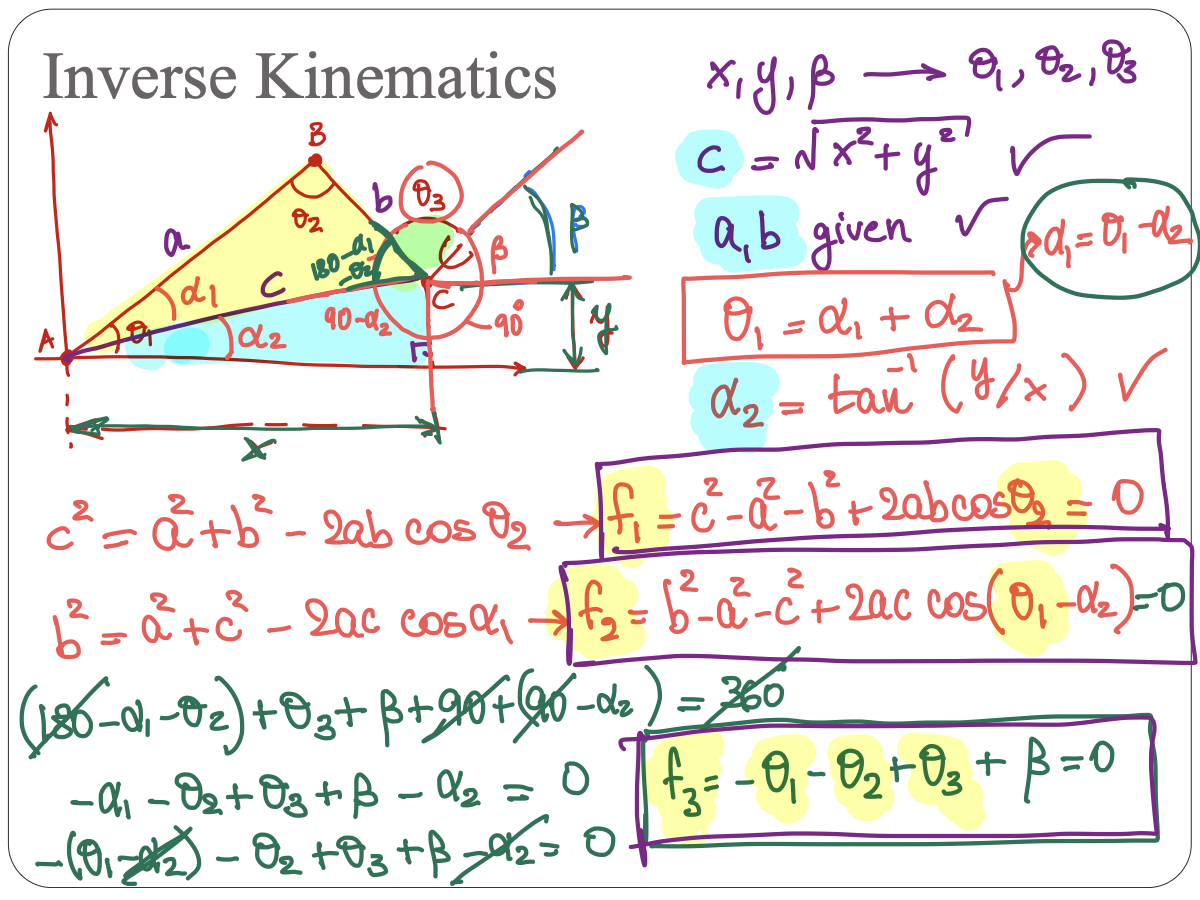

Apply the cosine rule to triangle $ABC$:
$$c^2=a^2+b^2-2ab\cos\theta_2,$$
$$b^2=a^2+c^2-2ac\cos\alpha_1.$$
Using $\alpha_1=\theta_1-\alpha_2$, retain the residuals in this sign convention:
$$\boxed{f_1=c^2-a^2-b^2+2ab\cos\theta_2=0,}$$
$$\boxed{f_2=b^2-a^2-c^2+2ac\cos(\theta_1-\alpha_2)=0.}$$

The angles around $C$ add to a full turn:
$$(180^\circ-\alpha_1-\theta_2)+\theta_3+\beta+90^\circ+(90^\circ-\alpha_2)=360^\circ.$$
Canceling the constant angles gives
$$-\alpha_1-\theta_2+\theta_3+\beta-\alpha_2=0.$$
Substitute $\alpha_1=\theta_1-\alpha_2$:
$$\boxed{f_3=-\theta_1-\theta_2+\theta_3+\beta=0.}$$
The geometry above is written in degrees to show the angle sum. The numerical code uses radians throughout.

For $\mathbf f=(f_1,f_2,f_3)^T$, the Jacobian is
$$J_{\mathbf f}=\begin{bmatrix}
0&-2ab\sin\theta_2&0\\
-2ac\sin(\theta_1-\alpha_2)&0&0\\
-1&-1&1
\end{bmatrix}.$$

The executable example uses $\mathbf F=-\mathbf f$. Therefore $J_{\mathbf F}=-J_{\mathbf f}$. Both conventions give the same Newton step because
$$J_{\mathbf f}\mathbf s=-\mathbf f
\quad\Longleftrightarrow\quad
J_{\mathbf F}\mathbf s=-\mathbf F.$$
The following implementation formulas explicitly use the uppercase $F$ convention.

### Residual convention used in the implementation

The two links have lengths $a,b$. The target endpoint is $C=(x_t,y_t)$ and the hand orientation is $\beta$. Unknown joint angles are $\boldsymbol\theta=(\theta_1,\theta_2,\theta_3)$, using the internal joint angles defined below.

Let
$$c=\sqrt{x_t^2+y_t^2},\qquad\alpha=\operatorname{atan2}(y_t,x_t).$$
The cosine rule and orientation relation give the residuals:
$$F_1=a^2+b^2-2ab\cos\theta_2-c^2,$$
$$F_2=a^2+c^2-2ac\cos(\theta_1-\alpha)-b^2,$$
$$F_3=\theta_1+\theta_2-\theta_3-\beta.$$
Negating any residual equation and its corresponding Jacobian row preserves the root set and Newton step.

The Jacobian is
$$\boxed{J(\boldsymbol\theta)=
\begin{bmatrix}
0&2ab\sin\theta_2&0\\
2ac\sin(\theta_1-\alpha)&0&0\\
1&1&-1
\end{bmatrix}.}$$

**Reachability:** $|a-b|\le c\le a+b$. At fully folded or extended configurations the Jacobian may become singular. The $c=0$ case requires a separate geometric treatment. `atan2` handles quadrants correctly, whereas `arcsin(y/c)` loses quadrant information.

The cosine equations encode distances but admit multiple periodic/sign branches. After solving, verify both the residual and the actual forward geometry for the chosen angle convention. For the illustrated elbow branch, the second link direction is $\theta_1+\theta_2-\pi$, and the hand direction is $\theta_1+\theta_2-\theta_3=\beta$.

### Derive the position equations

Let $A=(0,0)$ be the base, $B$ the elbow, and $C=(x_t,y_t)$ the hand. The triangle has $|AB|=a$, $|BC|=b$, and $|AC|=c$. Define $\theta_1$ as the direction of $AB$ and $\theta_2$ as the internal angle at $B$.

Applying the cosine rule at $B$ gives
$$c^2=a^2+b^2-2ab\cos\theta_2,$$
which is $F_1=0$. The angle between $AB$ and $AC$ on the illustrated branch is $\theta_1-\alpha$. Applying the cosine rule at $A$ gives
$$b^2=a^2+c^2-2ac\cos(\theta_1-\alpha),$$
which is $F_2=0$.

The condition $|a-b|\le c\le a+b$ follows from the triangle inequality. Targets outside this annulus cannot be reached by these two links.

### Derive the orientation equation

On the branch used here, the direction of the second link is
$$\gamma=\theta_1+\theta_2-\pi.$$
The angle $\theta_3$ between the hand direction and the reversed second-link direction satisfies
$$\beta=\gamma+\pi-\theta_3=\theta_1+\theta_2-\theta_3.$$
Thus $F_3=\theta_1+\theta_2-\theta_3-\beta=0$.

The orientation equation is linear in the angles, but the cosine equations are nonlinear. Newton therefore solves a coupled three-variable nonlinear system. Alternative elbow configurations require consistent angle conventions and a separate branch choice.

## 2. Numerical solution

$a=10$, $b=5$, target $(8,2)$, $\beta=\pi/4$. Compare `fsolve` with its internal derivative approximation, `fsolve` with the analytic Jacobian, and our explicit Newton solver. `fsolve` is a hybrid algorithm, so it need not follow the same iterates as plain Newton.

In [12]:
a_arm, b_arm = 10., 5.
xt_arm, yt_arm, beta_arm = 8., 2., np.pi/4
c_arm = np.hypot(xt_arm, yt_arm)
alpha_arm = np.arctan2(yt_arm, xt_arm)
if not (abs(a_arm-b_arm) < c_arm < a_arm+b_arm) or c_arm == 0:
    raise ValueError('This demo requires a reachable, nondegenerate target.')

def F_arm(theta):
    t1, t2, t3 = theta
    return np.array([
        a_arm*a_arm+b_arm*b_arm-2*a_arm*b_arm*np.cos(t2)-c_arm*c_arm,
        a_arm*a_arm+c_arm*c_arm-2*a_arm*c_arm*np.cos(t1-alpha_arm)-b_arm*b_arm,
        t1+t2-t3-beta_arm])

def J_arm(theta):
    t1, t2, _ = theta
    return np.array([[0., 2*a_arm*b_arm*np.sin(t2), 0.],
                     [2*a_arm*c_arm*np.sin(t1-alpha_arm), 0., 0.],
                     [1., 1., -1.]])

angle2_guess = np.arccos((a_arm*a_arm+b_arm*b_arm-c_arm*c_arm)/(2*a_arm*b_arm))
arm_start = np.array([np.pi/2, angle2_guess, np.pi/2+angle2_guess])
arm_solutions = {}
for label, jac in [('fsolve / approximate J', None), ('fsolve / analytic J', J_arm)]:
    sol, info, ier, message = opt.fsolve(F_arm, arm_start, fprime=jac,
                                        full_output=True, xtol=1e-11)
    if ier != 1 or la.norm(F_arm(sol), np.inf) > 1e-8:
        raise RuntimeError(message)
    arm_solutions = {**arm_solutions, label: sol}
    print(label, '| degrees:', np.degrees(sol), '| nfev:', info['nfev'],
          '| njev:', info.get('njev', 'internal approximation'))
arm_newton = newton_system(F_arm, J_arm, arm_start, tol=1e-10)
print('explicit Newton steps:', len(arm_newton.history)-1,
      '| residual:', arm_newton.residuals[-1])
assert np.allclose(J_arm(arm_start), fd_jacobian(F_arm, arm_start), atol=2e-5)

fsolve / approximate J | degrees: [43.9169153  55.24977425 54.16668955] | nfev: 15 | njev: internal approximation
fsolve / analytic J | degrees: [43.9169153  55.24977425 54.16668955] | nfev: 16 | njev: 2
explicit Newton steps: 5 | residual: 1.4210854715202004e-13


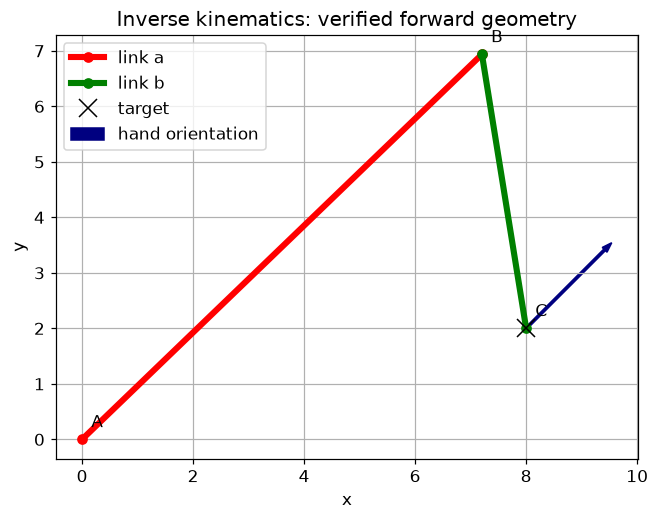

In [13]:
arm_theta = arm_newton.root
elbow = a_arm*np.array([np.cos(arm_theta[0]), np.sin(arm_theta[0])])
second_direction = arm_theta[0]+arm_theta[1]-np.pi
endpoint = elbow+b_arm*np.array([np.cos(second_direction), np.sin(second_direction)])
hand_direction = arm_theta[0]+arm_theta[1]-arm_theta[2]
assert np.allclose(endpoint, [xt_arm,yt_arm], atol=1e-8)
assert abs(hand_direction-beta_arm) < 1e-8
fig, ax = plt.subplots(figsize=(8,5))
ax.plot([0,elbow[0]], [0,elbow[1]], '-or', lw=4, label='link a')
ax.plot([elbow[0],endpoint[0]], [elbow[1],endpoint[1]], '-og', lw=4, label='link b')
ax.plot(xt_arm, yt_arm, 'kx', ms=12, label='target')
ax.arrow(endpoint[0], endpoint[1], 2*np.cos(hand_direction),
         2*np.sin(hand_direction), width=.04, color='navy', label='hand orientation')
for label, point in [('A', [0,0]), ('B',elbow), ('C',endpoint)]:
    ax.annotate(label, point, xytext=(6,8), textcoords='offset points')
ax.set(aspect='equal', xlabel='x', ylabel='y', title='Inverse kinematics: verified forward geometry')
ax.legend(); plt.show()

The reported `nfev` counts actual vector-residual evaluations for that SciPy run; `njev` counts analytic Jacobian calls when available. These counts can vary by library version. A Newton **iteration count** is not a function-evaluation count. Providing a Jacobian often reduces numerical-difference evaluations, but it does not guarantee a smaller total runtime for every problem.

# VIII Review and Numerical Verification

## 1. Checks before trusting a result

1. Did the required bracket/derivative/Jacobian assumptions hold?
2. Was the return a root estimate, a step vector, or an interval-width bound?
3. Is the final residual small in a sensible scale?
4. Was a maximum iteration limit enforced, and was solver status checked?
5. Are multiple roots or geometry branches possible?
6. Does a claimed cost count scalar values, vector calls, derivatives, factorizations, or iterations?

## 2. Executable checks

The following checks cover the main numerical invariants and the failure cases used in the notes. Known true roots are used only for verification and error analysis, never as a general solver's stopping condition.

In [14]:
def expect_error(error_type, operation):
    try:
        operation()
    except error_type:
        return
    raise AssertionError(f'Expected {error_type.__name__}')

assert abs(new_exp.root-root_exp) < 1e-10
assert abs(sec_exp.root-root_exp) < 1e-10
assert bisection(lambda x:x, 0., 1.).root == 0.
expect_error(ValueError, lambda:bisection(lambda x:x*x+1, -1., 1.))
expect_error(ValueError, lambda:bisection(f_exp, -2., 2., width_tol=-1))
expect_error(ZeroDivisionError, lambda:newton_scalar(lambda x:2*x-x*x, lambda x:2-2*x, 1.))
expect_error(ZeroDivisionError, lambda:secant(lambda x:x*x+1, -1., 1.))
expect_error(RuntimeError, lambda:newton_scalar(f_exp, D_exp, 10., maxiter=1))
expect_error(la.LinAlgError, lambda:newton_system(F_system, J_system, [1.,.5]))
assert np.allclose(sys_left.root, [0.,1.], atol=1e-9)
assert np.allclose(sys_right.root, [2.,0.], atol=1e-9)
assert sys_fd.residuals[-1] < 1e-10
assert np.array_equal(probe, probe_saved)

# Independently verify the PrairieLearn step and triangular example.
F_pl_step = lambda z:np.array([(z[0]-z[1])**2-7, z[1]**3-2*z[0]])
J_pl_step = lambda z:np.array([[2*(z[0]-z[1]),-2*(z[0]-z[1])],[-2.,3*z[1]**2]])
assert np.allclose(la.solve(J_pl_step([3.,2.]), -F_pl_step([3.,2.])), [3.4,.4])
F_tri = lambda z:np.array([z[0]+2, 5*z[0]**2+z[1]-5])
J_tri = lambda z:np.array([[1.,0.],[10*z[0],1.]])
tri_result = newton_system(F_tri, J_tri, [1.,0.])
assert np.allclose(tri_result.history[1], [-2.,30.])
assert np.allclose(tri_result.root, [-2.,-15.])
print('All numerical and failure-case checks passed.')

All numerical and failure-case checks passed.
